# Gerekli Kütüphaneler


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Veri Okuma

In [ ]:
df = pd.read_csv("araba.csv")

print("Veri başarıyla okundu! İlk 5 satır:")
df.head()

Veri başarıyla okundu! İlk 5 satır:


,fiyat,marka,seri,model,yil,kilometre,vites_tipi,yakit_tipi,kasa_tipi,motor_hacmi,motor_gucu,cekis,ortalama_yakit_tuketimi,tramer,sehir,boya,degisen
0,1169000,Renault,Megane,1.3 TCe Joy Comfort,2022,124000.0,Otomatik,Benzin,Sedan,1400,150,Önden Çekiş,0.0,71300.0,Adana,1,0
1,1520000,Skoda,Octavia,1.0 e-Tec Elite,2022,99000.0,Otomatik,Hibrit,Sedan,1400,125,Önden Çekiş,0.0,56060.0,Adana,0,1
2,469999,Peugeot,207,1.4 Trendy,2009,207500.0,Düz,LPG & Benzin,Hatchback/5,1360,91,Önden Çekiş,6.3,0.0,Adana,0,0
3,1150000,Audi,A4,A4 Sedan 2.0 TDI Quattro,2013,219000.0,Otomatik,Dizel,Sedan,2000,200,4WD (Sürekli),0.0,0.0,Adana,1,4
4,1359000,BMW,5 Serisi,520Li,2013,335000.0,Otomatik,Benzin,Sedan,2000,200,Arkadan İtiş,0.0,0.0,Adana,0,0


# Veri Temizliği

In [ ]:
print(" Veri temizliği ve düzenleme işlemi başlıyor...")


def temizle_sayi_yap(sutun_adi):
    if df[sutun_adi].dtype == 'object':
        df[sutun_adi] = df[sutun_adi].astype(str).str.replace('TL', '')
        df[sutun_adi] = df[sutun_adi].astype(str).str.replace('km', '')
        df[sutun_adi] = df[sutun_adi].astype(str).str.replace('.', '')
        df[sutun_adi] = df[sutun_adi].astype(str).str.replace(',', '')
        df[sutun_adi] = df[sutun_adi].astype(str).str.strip()
        df[sutun_adi] = pd.to_numeric(df[sutun_adi], errors='coerce')

temizle_sayi_yap('fiyat')
temizle_sayi_yap('kilometre')

df.dropna(inplace=True)



Q1 = df['fiyat'].quantile(0.25)
Q3 = df['fiyat'].quantile(0.75)
IQR = Q3 - Q1

alt_sinir = Q1 - 1.5 * IQR
ust_sinir = Q3 + 1.5 * IQR


df = df[(df['fiyat'] >= alt_sinir) & (df['fiyat'] <= ust_sinir)]

print(f"Uçuk fiyatlar temizlendikten sonra araç sayısı: {len(df)}")


le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col].astype(str))

print("\n Veri seti temizlendi ve eğitime hazır!")
print(df.head())

 Veri temizliği ve düzenleme işlemi başlıyor...
Uçuk fiyatlar temizlendikten sonra araç sayısı: 47890

 Veri seti temizlendi ve eğitime hazır!
     fiyat  marka  seri  model   yil  kilometre  vites_tipi  yakit_tipi  \
0  1169000     32   232    428  2022   124000.0           1           0   
1  1520000     36   249    117  2022    99000.0           1           3   
2   469999     30    18    829  2009   207500.0           0           4   
3  1150000      1    68   2456  2013   219000.0           1           1   
4  1359000      2    49   2291  2013   335000.0           1           0   

   kasa_tipi  motor_hacmi  motor_gucu  cekis  ortalama_yakit_tuketimi  \
0          9         1400         150      4                      0.0   
1          9         1400         125      4                      0.0   
2          4         1360          91      4                      6.3   
3          9         2000         200      1                      0.0   
4          9         2000         200    

# Model Eğitimi

In [ ]:
X = df.drop('fiyat', axis=1)
y = df['fiyat']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Eğitim Verisi Sayısı: {len(X_train)}")
print(f"Test Verisi Sayısı: {len(X_test)}")


print("\nModel eğitiliyor...")
gbm_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)


gbm_model.fit(X_train, y_train)
print("Model eğitimi tamamlandı! Şimdi sonuçlara bakabilirsiniz.")

Eğitim Verisi Sayısı: 38312
Test Verisi Sayısı: 9578

Model eğitiliyor...
Model eğitimi tamamlandı! Şimdi sonuçlara bakabilirsiniz.


# Sonuçlar ve Grafikler

 MODEL PERFORMANS RAPORU
 R2 Score (Başarı):  0.951  
 MAE (Ortalama Hata): 58,003 TL  
 RMSE (Karesel Hata): 82,105 TL  


/tmp/ipython-input-858750006.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_imp, y=feature_imp.index, palette="viridis")


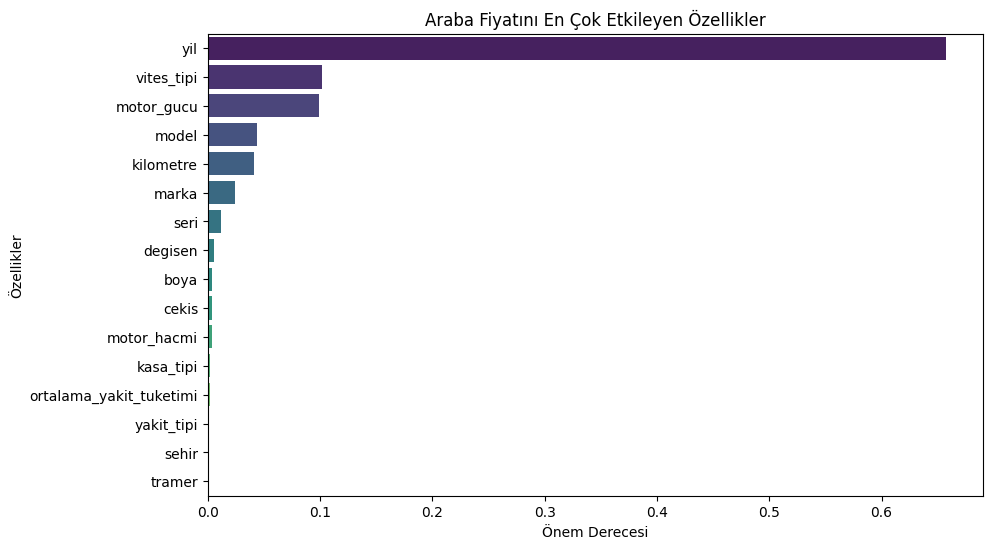

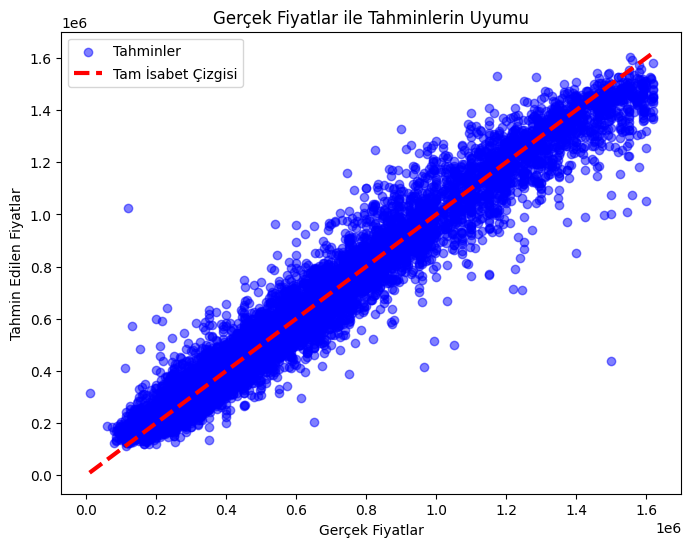


 Rastgele 5 Tahmin 
       Gerçek   Tahmin
6921  1263000  1360752
7459   360000   319005
6759   570000   622175
5352   250000   191850
7703   210000   192311


In [ ]:
tahminler = gbm_model.predict(X_test)

r2 = r2_score(y_test, tahminler)
mse = mean_squared_error(y_test, tahminler)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, tahminler)


print(f" MODEL PERFORMANS RAPORU")

print(f" R2 Score (Başarı):  {r2:.3f}  ")
print(f" MAE (Ortalama Hata): {mae:,.0f} TL  ")
print(f" RMSE (Karesel Hata): {rmse:,.0f} TL  ")


# araba fiyatını etkileyen özellikler grafiği
feature_imp = pd.Series(gbm_model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_imp, y=feature_imp.index, palette="viridis")
plt.title("Araba Fiyatını En Çok Etkileyen Özellikler")
plt.xlabel("Önem Derecesi")
plt.ylabel("Özellikler")
plt.show()

# gerçek tahminlerle uyum grafiği
plt.figure(figsize=(8, 6))
plt.scatter(y_test, tahminler, alpha=0.5, color='blue', label='Tahminler')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=3, label='Tam İsabet Çizgisi')
plt.xlabel("Gerçek Fiyatlar")
plt.ylabel("Tahmin Edilen Fiyatlar")
plt.title("Gerçek Fiyatlar ile Tahminlerin Uyumu")
plt.legend()
plt.show()

# rastgele tahmin vs gerçek tablosu
ornek_tablo = pd.DataFrame({'Gerçek': y_test.values, 'Tahmin': tahminler.astype(int)})
print("\n Rastgele 5 Tahmin ")
print(ornek_tablo.sample(5))